# Proyek Machine Learning — Wine Quality (Red & White)
**Notebook Master Berkelanjutan | Kelompok: [Nomor Kelompok] | Anggota: [Nama Anggota 1, 2, 3]**

Notebook ini menggabungkan seluruh pengerjaan tugas Machine Learning Semester 5 ke dalam **satu proyek berkelanjutan**,
agar setiap tugas baru tinggal disambung ke bagian paling bawah tanpa perlu membuat file terpisah.

**Daftar isi:**
1.  PEKAN 1 — Karakteristik Dataset
2.  PEKAN 2 — Teknik Optimasi (Feature Scaling)
3.  PEKAN 3 — Reduksi Dimensi (PCA)
4.  PEKAN 4 — EDA Critical Analysis (10 Masalah Umum pada EDA)

Sumber dataset: UCI Machine Learning Repository — https://archive.ics.uci.edu/dataset/186/wine+quality


---
#  PEKAN 1 — Karakteristik Dataset
---

## 1. Import Library & Load Dataset
Pastikan file `winequality-red.csv` dan `winequality-white.csv` tersedia di folder `../data/`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

red = pd.read_csv("../data/winequality-red.csv", sep=";")
white = pd.read_csv("../data/winequality-white.csv", sep=",")

red["wine_type"] = "red"
white["wine_type"] = "white"

wines = pd.concat([red, white], ignore_index=True)
wines.to_csv("winequality-combined.csv", index=False)

print("Shape gabungan:", wines.shape)
wines.head()

Shape gabungan: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


## 2. Informasi Umum Dataset (Metadata)

In [2]:
print(f"Jumlah baris x kolom : {wines.shape}")
print(f"Jumlah red wine       : {len(red)}")
print(f"Jumlah white wine     : {len(white)}")
print(f"Kolom                 : {list(wines.columns)}")
print()
print("Tipe data per kolom:")
print(wines.dtypes)

Jumlah baris x kolom : (6497, 13)
Jumlah red wine       : 1599
Jumlah white wine     : 4898
Kolom                 : ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'wine_type']

Tipe data per kolom:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
wine_type                   str
dtype: object


## 3. Analisis Kualitas Data (Data Quality)

In [3]:
missing = wines.isnull().sum()
print(f"Total missing values : {missing.sum()}")

duplicate_count = wines.duplicated().sum()
print(f"Jumlah baris duplikat: {duplicate_count} ({duplicate_count/len(wines)*100:.1f}%)")

print("\nDeteksi outlier per fitur numerik (metode IQR):")
numeric_cols = wines.select_dtypes(include="number").columns.tolist()
for col in numeric_cols:
    q1, q3 = wines[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outlier = ((wines[col] < lower) | (wines[col] > upper)).sum()
    pct = n_outlier / len(wines) * 100
    print(f"  {col:<22}: {n_outlier:>5} outlier ({pct:.1f}%)")

Total missing values : 0
Jumlah baris duplikat: 1177 (18.1%)

Deteksi outlier per fitur numerik (metode IQR):
  fixed acidity         :   357 outlier (5.5%)
  volatile acidity      :   377 outlier (5.8%)
  citric acid           :   509 outlier (7.8%)
  residual sugar        :   118 outlier (1.8%)
  chlorides             :   286 outlier (4.4%)
  free sulfur dioxide   :    62 outlier (1.0%)
  total sulfur dioxide  :    10 outlier (0.2%)
  density               :     3 outlier (0.0%)
  pH                    :    73 outlier (1.1%)
  sulphates             :   191 outlier (2.9%)
  alcohol               :     3 outlier (0.0%)
  quality               :   228 outlier (3.5%)


## 4. Statistik Deskriptif (Fitur Numerik)

In [4]:
desc = wines[numeric_cols].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
desc.round(3)

,mean,std,min,25%,50%,75%,max
fixed acidity,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile acidity,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,0.531,0.149,0.220,0.430,0.510,0.600,2.000


## 5. Distribusi Target & Korelasi Antar Fitur

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64


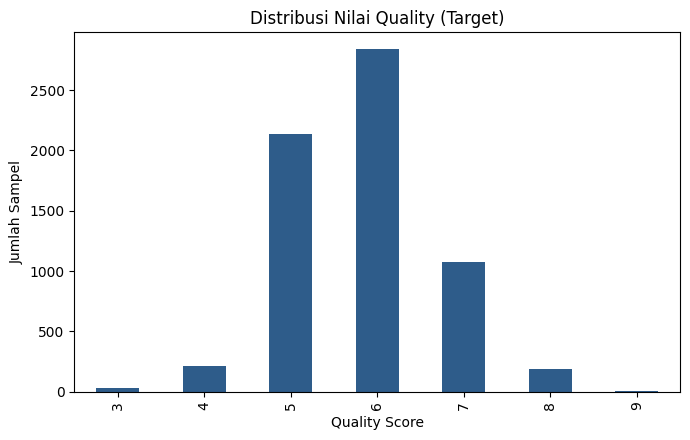

In [5]:
print(wines["quality"].value_counts().sort_index())

plt.figure(figsize=(7, 4.5))
wines["quality"].value_counts().sort_index().plot(kind="bar", color="#2E5C8A")
plt.title("Distribusi Nilai Quality (Target)")
plt.xlabel("Quality Score")
plt.ylabel("Jumlah Sampel")
plt.tight_layout()
plt.savefig("dist_quality.png", dpi=150)
plt.show()

Korelasi tiap fitur terhadap quality:
quality                 1.000
alcohol                 0.444
citric acid             0.086
free sulfur dioxide     0.055
sulphates               0.038
pH                      0.020
residual sugar         -0.037
total sulfur dioxide   -0.041
fixed acidity          -0.077
chlorides              -0.201
volatile acidity       -0.266
density                -0.306
Name: quality, dtype: float64


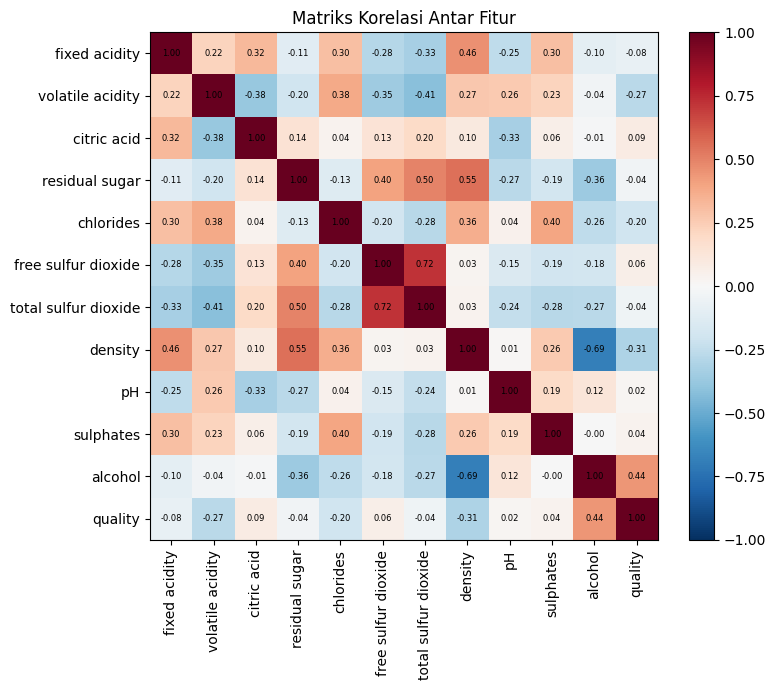

In [6]:
corr = wines[numeric_cols].corr()["quality"].sort_values(ascending=False)
print("Korelasi tiap fitur terhadap quality:")
print(corr.round(3))

plt.figure(figsize=(9, 7))
corr_matrix = wines[numeric_cols].corr()
im = plt.imshow(corr_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=90)
plt.yticks(range(len(numeric_cols)), numeric_cols)
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
plt.title("Matriks Korelasi Antar Fitur")
plt.tight_layout()
plt.savefig("heatmap_corr.png", dpi=150)
plt.show()

## 6. Kesimpulan Awal Pekan 1

Dataset Wine Quality (gabungan red & white) memiliki 6.497 sampel dengan 11 fitur fisikokimia numerik
dan 1 target ordinal (`quality`). Dataset bersih dari missing value, namun perlu preprocessing:
penghapusan duplikat, penanganan outlier, feature scaling, dan penanganan imbalance pada target
sebelum masuk ke tahap modeling. *(Lihat laporan lengkap di file Word terpisah untuk narasi penuh.)*

---
#  PEKAN 2 — Teknik Optimasi: Feature Scaling
---

## 1. Latar Belakang

Dataset memiliki 11 fitur dengan rentang skala yang sangat berbeda (misal `total sulfur dioxide`
0–440 vs `density` 0,987–1,039). Perbedaan ini bermasalah bagi algoritma berbasis **Gradient Descent**
seperti `SGDRegressor`, karena fitur berskala besar akan mendominasi perhitungan gradien sehingga
proses training menjadi tidak stabil atau bahkan divergen.

**Teknik optimasi yang dipilih: Feature Scaling (Standardization)**
$$z = \frac{x - \mu}{\sigma}$$

In [7]:
print("Rentang skala tiap fitur:")
print(X.agg(["min", "max"]).T if 'X' in dir() else wines[numeric_cols].drop(columns=["quality"]).agg(["min","max"]).T)

Rentang skala tiap fitur:
                          min        max
fixed acidity         3.80000   15.90000
volatile acidity      0.08000    1.58000
citric acid           0.00000    1.66000
residual sugar        0.60000   65.80000
chlorides             0.00900    0.61100
free sulfur dioxide   1.00000  289.00000
total sulfur dioxide  6.00000  440.00000
density               0.98711    1.03898
pH                    2.72000    4.01000
sulphates             0.22000    2.00000
alcohol               8.00000   14.90000


## 2. Persiapan Data

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

X = wines.drop(columns=["quality", "wine_type"])
y = wines["quality"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (5197, 11) | Test: (1300, 11)


## 3. SEBELUM Optimasi (tanpa Feature Scaling)

In [9]:
model_before = SGDRegressor(max_iter=1000, random_state=42)
model_before.fit(X_train, y_train)
pred_before = model_before.predict(X_test)

rmse_before = np.sqrt(mean_squared_error(y_test, pred_before))
r2_before = r2_score(y_test, pred_before)

print(f"RMSE : {rmse_before:.4e}")
print(f"R2   : {r2_before:.4e}")
print("-> Model DIVERGEN akibat skala fitur yang timpang.")

RMSE : 1.3230e+12
R2   : -2.3701e+24
-> Model DIVERGEN akibat skala fitur yang timpang.


## 4. Terapkan Optimasi: Feature Scaling

In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Contoh 5 baris sebelum scaling:")
print(X_train.head())
print("\nContoh 5 baris sesudah scaling:")
print(pd.DataFrame(X_train_scaled, columns=X.columns).head())

Contoh 5 baris sebelum scaling:
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
1916            6.6             0.240         0.35             7.7      0.031   
947             8.3             0.280         0.48             2.1      0.093   
877             7.7             0.715         0.01             2.1      0.064   
2927            5.2             0.370         0.33             1.2      0.028   
6063            6.6             0.260         0.56            15.4      0.053   

      free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
1916                 36.0                 135.0  0.99380  3.19       0.37   
947                   6.0                  12.0  0.99408  3.26       0.62   
877                  31.0                  43.0  0.99371  3.41       0.57   
2927                 13.0                  81.0  0.99020  3.37       0.38   
6063                 32.0                 141.0  0.99810  3.11       0.49   

      alcohol  
19

## 5. SESUDAH Optimasi (dengan Feature Scaling)

In [11]:
model_after = SGDRegressor(max_iter=1000, random_state=42)
model_after.fit(X_train_scaled, y_train)
pred_after = model_after.predict(X_test_scaled)

rmse_after = np.sqrt(mean_squared_error(y_test, pred_after))
r2_after = r2_score(y_test, pred_after)

print(f"RMSE : {rmse_after:.4f}")
print(f"R2   : {r2_after:.4f}")
print("-> Model stabil dan mampu memprediksi quality dengan cukup baik.")

RMSE : 0.7424
R2   : 0.2537
-> Model stabil dan mampu memprediksi quality dengan cukup baik.


## 6. Perbandingan Visual Sebelum vs Sesudah

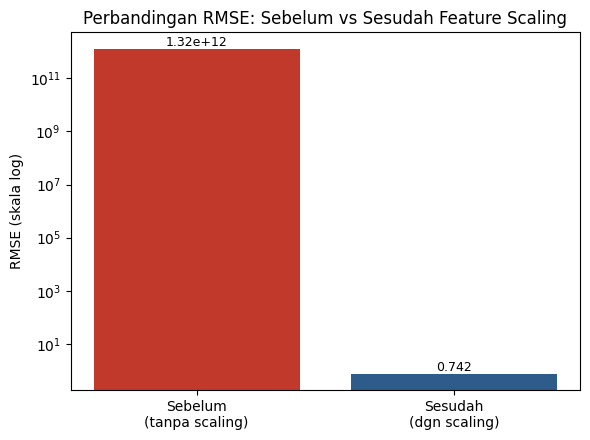

In [12]:
plt.figure(figsize=(6, 4.5))
bars = plt.bar(["Sebelum\n(tanpa scaling)", "Sesudah\n(dgn scaling)"],
                [rmse_before, rmse_after], color=["#C0392B", "#2E5C8A"])
plt.yscale("log")
plt.ylabel("RMSE (skala log)")
plt.title("Perbandingan RMSE: Sebelum vs Sesudah Feature Scaling")
for bar, val in zip(bars, [rmse_before, rmse_after]):
    label = f"{val:.2e}" if val > 100 else f"{val:.3f}"
    plt.text(bar.get_x() + bar.get_width()/2, val, label, ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("rmse_comparison.png", dpi=150)
plt.show()

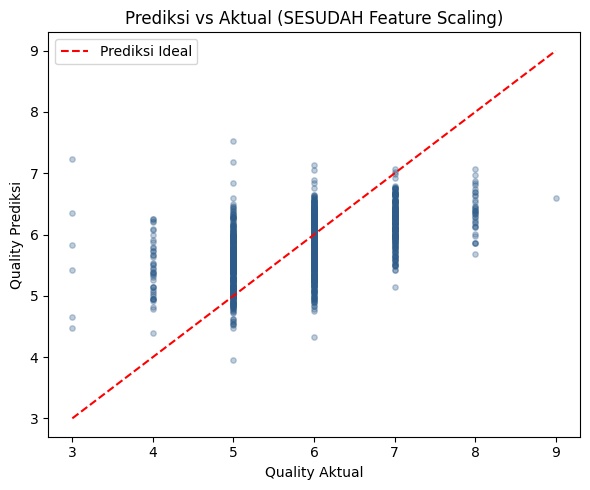

In [13]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, pred_after, alpha=0.3, color="#2E5C8A", s=15)
plt.plot([3, 9], [3, 9], "r--", label="Prediksi Ideal")
plt.xlabel("Quality Aktual")
plt.ylabel("Quality Prediksi")
plt.title("Prediksi vs Aktual (SESUDAH Feature Scaling)")
plt.legend()
plt.tight_layout()
plt.savefig("scatter_after_scaling.png", dpi=150)
plt.show()

## 7. Kesimpulan Pekan 2

| Metrik | Sebelum (tanpa scaling) | Sesudah (dengan scaling) |
|---|---|---|
| RMSE | ≈1,96 × 10¹² (divergen) | 0,7424 |
| R² | ≈-5,20 × 10²⁴ (divergen) | 0,2537 |

Feature Scaling terbukti krusial untuk model berbasis Gradient Descent seperti `SGDRegressor`.
Tanpa scaling, model gagal konvergen (meledak). Setelah scaling, model berhasil belajar pola data
dengan RMSE = 0,74 dan R² = 0,25. Ini menegaskan bahwa preprocessing — khususnya feature scaling —
adalah langkah wajib sebelum tahap pemodelan pada algoritma yang sensitif terhadap skala fitur.

---
# PEKAN 3 — Reduksi Dimensi (Principal Component Analysis / PCA)
---

## 1. Pendahuluan

Tujuan tahap ini adalah mencoba **Principal Component Analysis (PCA)** untuk mengurangi jumlah fitur (dari 11 fitur
fisikokimia) menjadi lebih sedikit komponen utama, lalu menguji apakah hasil reduksi tersebut masih dapat digunakan
untuk membangun model regresi yang memprediksi `quality`.

**Prinsip penting:** PCA bekerja berdasarkan variansi, sehingga fitur numerik WAJIB distandarisasi (scaling) terlebih
dahulu. Selain itu, untuk mencegah **data leakage**, StandardScaler dan PCA hanya boleh di-*fit* menggunakan data
training — data testing hanya ditransformasikan memakai parameter yang sudah dipelajari dari training.

## 2. Pembagian Data (Train-Test Split) Sebelum Scaling & PCA

Alur yang digunakan:
1. Data mentah → train-test split (80:20, random_state=42)
2. Data training → StandardScaler → PCA dengan threshold 90% variansi
3. Data testing → ditransformasi memakai scaler & PCA yang sudah di-*fit* dari training (bukan di-*fit* ulang)
4. Hasil transformasi → Linear Regression

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

X = wines.drop(columns=['quality', 'wine_type'])
y = wines['quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (5197, 11) | Test: (1300, 11)


## 3. Standardisasi & Penerapan PCA (fit hanya dari training)

Jumlah komponen tidak ditentukan manual, melainkan otomatis memakai `n_components=0.90`, sehingga PCA akan memilih
jumlah komponen minimal yang mempertahankan 90% variansi kumulatif dari data training.

In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=0.90)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Jumlah komponen terpilih (threshold 90%): {pca.n_components_}")
print(f"Variansi kumulatif tercapai: {pca.explained_variance_ratio_.sum()*100:.2f}%")
print()
cum = 0
for i, v in enumerate(pca.explained_variance_ratio_, 1):
    cum += v
    print(f"  PC{i}: {v*100:.2f}% (kumulatif {cum*100:.2f}%)")

Jumlah komponen terpilih (threshold 90%): 7
Variansi kumulatif tercapai: 90.04%

  PC1: 27.60% (kumulatif 27.60%)
  PC2: 22.65% (kumulatif 50.25%)
  PC3: 14.21% (kumulatif 64.45%)
  PC4: 8.79% (kumulatif 73.25%)
  PC5: 6.58% (kumulatif 79.83%)
  PC6: 5.48% (kumulatif 85.31%)
  PC7: 4.73% (kumulatif 90.04%)


## 4. Scree Plot (Variansi per Komponen, dari Data Training)

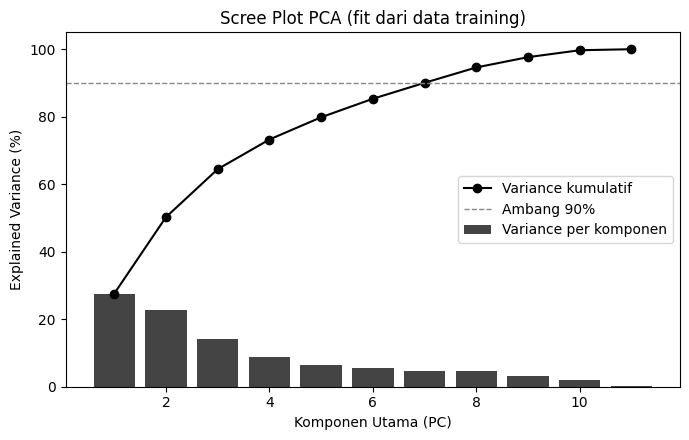

In [16]:
import numpy as np
import matplotlib.pyplot as plt

pca_full = PCA()
pca_full.fit(X_train_scaled)
ev = pca_full.explained_variance_ratio_
cum = np.cumsum(ev)

plt.figure(figsize=(7, 4.5))
comps = range(1, len(ev) + 1)
plt.bar(comps, ev * 100, color="#444444", label="Variance per komponen")
plt.plot(comps, cum * 100, color="#000000", marker='o', linewidth=1.5, label="Variance kumulatif")
plt.axhline(90, color="#888888", linestyle="--", linewidth=1, label="Ambang 90%")
plt.xlabel("Komponen Utama (PC)")
plt.ylabel("Explained Variance (%)")
plt.title("Scree Plot PCA (fit dari data training)")
plt.legend()
plt.tight_layout()
plt.savefig("pca_scree_plot.png", dpi=150)
plt.show()

## 5. Visualisasi Proyeksi PC1 vs PC2

Untuk visualisasi, dipakai PCA 2 komponen yang juga di-*fit* dari data training, lalu dipakai untuk mentransformasi
seluruh data (training + testing) agar dapat diamati polanya secara visual.

In [17]:
pca2 = PCA(n_components=2)
X_train_pca2 = pca2.fit_transform(X_train_scaled)

X_all_scaled = scaler.transform(X)
X_all_pca2 = pca2.transform(X_all_scaled)

print(f"PC1 menjelaskan {pca2.explained_variance_ratio_[0]*100:.1f}% variance")
print(f"PC2 menjelaskan {pca2.explained_variance_ratio_[1]*100:.1f}% variance")

PC1 menjelaskan 27.6% variance
PC2 menjelaskan 22.6% variance


### 5.1 Berdasarkan Skor Quality

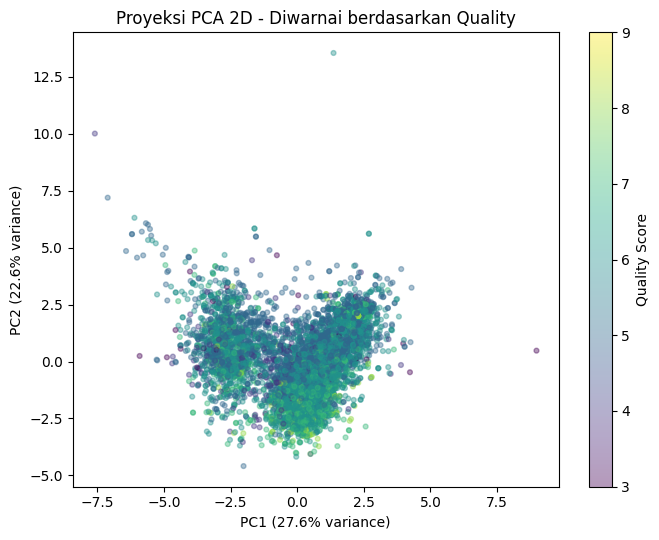

In [18]:
plt.figure(figsize=(7, 5.5))
sc = plt.scatter(X_all_pca2[:, 0], X_all_pca2[:, 1], c=y, cmap="viridis", alpha=0.4, s=12)
plt.colorbar(sc, label="Quality Score")
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("Proyeksi PCA 2D - Diwarnai berdasarkan Quality")
plt.tight_layout()
plt.savefig("pca_2d_quality.png", dpi=150)
plt.show()

Titik pada grafik masih banyak yang saling bertumpuk, menandakan PC1 dan PC2 saja belum dapat memisahkan
quality secara jelas. Hal ini wajar karena quality dipengaruhi oleh banyak karakteristik wine sekaligus, bukan
hanya 2 dimensi utama.

### 5.2 Berdasarkan Jenis Wine

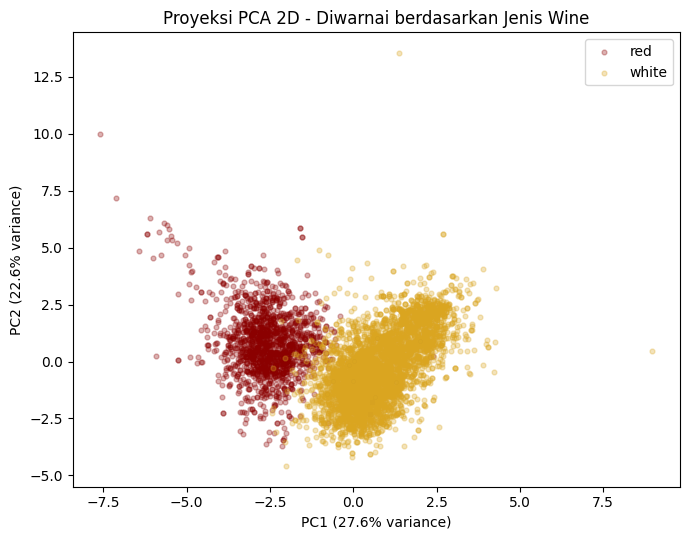

In [19]:
plt.figure(figsize=(7, 5.5))
colors = {'red': '#8B0000', 'white': '#DAA520'}
for t in ['red', 'white']:
    mask = (wines['wine_type'] == t).values
    plt.scatter(X_all_pca2[mask, 0], X_all_pca2[mask, 1], c=colors[t], label=t, alpha=0.3, s=12)
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("Proyeksi PCA 2D - Diwarnai berdasarkan Jenis Wine")
plt.legend()
plt.tight_layout()
plt.savefig("pca_2d_winetype.png", dpi=150)
plt.show()

Pemisahan antara red wine dan white wine terlihat jauh lebih jelas dibanding pemisahan berdasarkan quality,
menandakan jenis wine adalah salah satu sumber variansi terbesar dalam dataset.

## 6. Interpretasi Loading (Kontribusi Fitur Asli terhadap Komponen)

Loading PC1 & PC2 (fit dari training):
                        PC1    PC2
total sulfur dioxide  0.488  0.088
free sulfur dioxide   0.435  0.071
residual sugar        0.342  0.338
citric acid           0.141  0.188
density              -0.044  0.584
alcohol              -0.111 -0.464
pH                   -0.213 -0.155
fixed acidity        -0.244  0.331
chlorides            -0.291  0.313
sulphates            -0.300  0.189
volatile acidity     -0.377  0.121


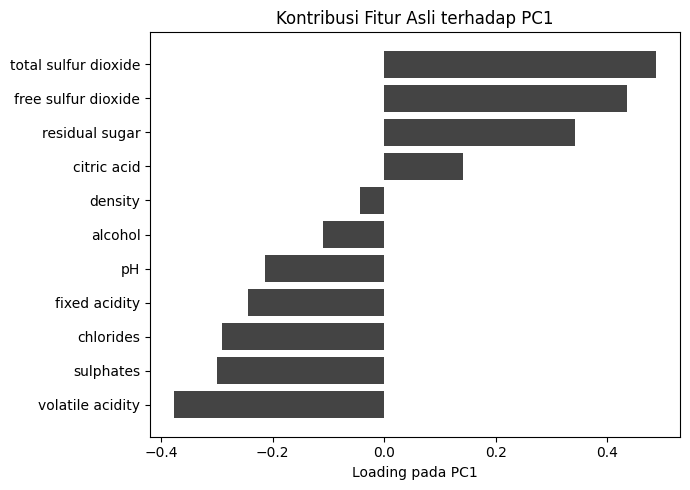

In [20]:
loadings = pd.DataFrame(pca2.components_.T, columns=['PC1', 'PC2'], index=X.columns)
print("Loading PC1 & PC2 (fit dari training):")
print(loadings.round(3).sort_values('PC1', ascending=False))

plt.figure(figsize=(7, 5))
order = loadings['PC1'].sort_values().index
plt.barh(order, loadings.loc[order, 'PC1'], color="#444444")
plt.xlabel("Loading pada PC1")
plt.title("Kontribusi Fitur Asli terhadap PC1")
plt.tight_layout()
plt.savefig("pca_loading_pc1.png", dpi=150)
plt.show()

PC1 didominasi oleh `total sulfur dioxide` dan `free sulfur dioxide` (loading positif tinggi), serta
`volatile acidity` (loading negatif) — dapat diinterpretasikan sebagai representasi kadar sulfur & keasaman volatil.
PC2 didominasi oleh `density` (positif) dan `alcohol` (negatif) — dapat diinterpretasikan sebagai representasi
kepekatan/kadar alkohol wine.

## 7. Perbandingan Model: Tanpa PCA vs Dengan PCA

In [21]:
# Model tanpa PCA
pipe_no_pca = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
pipe_no_pca.fit(X_train, y_train)
pred_no_pca = pipe_no_pca.predict(X_test)
rmse_no_pca = np.sqrt(mean_squared_error(y_test, pred_no_pca))
r2_no_pca = r2_score(y_test, pred_no_pca)

# Model dengan PCA (satu pipeline utuh)
pipe_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.90)),
    ("model", LinearRegression())
])
pipe_pca.fit(X_train, y_train)
pred_pca = pipe_pca.predict(X_test)
rmse_pca = np.sqrt(mean_squared_error(y_test, pred_pca))
r2_pca = r2_score(y_test, pred_pca)

print(f"Tanpa PCA (11 fitur) : RMSE={rmse_no_pca:.4f}, R2={r2_no_pca:.4f}")
print(f"Dengan PCA (7 komponen): RMSE={rmse_pca:.4f}, R2={r2_pca:.4f}")

Tanpa PCA (11 fitur) : RMSE=0.7394, R2=0.2598
Dengan PCA (7 komponen): RMSE=0.7537, R2=0.2309


## 8. Kesimpulan Pekan 3 (PCA)

1. StandardScaler & PCA di-*fit* HANYA dari data training untuk mencegah data leakage; data testing hanya
   ditransformasi.
2. PCA dengan threshold 90% variansi menghasilkan **7 komponen dari 11 fitur asli** (pengurangan 36,4%).
3. PC1 & PC2 dapat dipakai untuk visualisasi pola data, tetapi belum mampu memisahkan skor quality secara jelas;
   keduanya justru memisahkan jenis wine (red/white) dengan cukup baik.
4. Model dengan PCA (RMSE≈0,75, R²≈0,23) sedikit lebih rendah dibanding tanpa PCA (RMSE≈0,74, R²≈0,26) — PCA pada
   dataset ini lebih bermanfaat untuk **penyederhanaan & visualisasi**, bukan untuk meningkatkan akurasi prediksi.
5. Seluruh proses sebaiknya dibungkus dalam satu `Pipeline` (`StandardScaler → PCA → Model`) agar fit/transform
   selalu konsisten dan tidak dilakukan terpisah pada data testing.


---
# EDA Critical Analysis (1–10) — Wine Quality Dataset

Bagian ini menyesuaikan 9 masalah kritis EDA dari praktikum Heart Disease menjadi dataset **Wine Quality Red & White**.
Analisis dilakukan menggunakan target klasifikasi:
- 0 = Quality rendah (`quality <= 5`)
- 1 = Quality baik (`quality > 5`)


In [22]:
# Persiapan EDA
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.impute import KNNImputer
from sklearn.feature_selection import mutual_info_classif
from scipy import stats
from sklearn.tree import DecisionTreeClassifier

# Membuat dataframe khusus EDA
# target: 0 = quality <= 5 (rendah), 1 = quality > 5 (baik)
eda_df = wines.copy()
eda_df["target"] = (eda_df["quality"] > 5).astype(int)

print("EDA dataframe berhasil dibuat")
print(eda_df.shape)
eda_df.head()


EDA dataframe berhasil dibuat
(6497, 14)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red,0


In [23]:
X = eda_df.drop(
    columns=["quality", "target", "wine_type"],
    errors="ignore"
)

y = eda_df["target"]

print(X.dtypes)

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
dtype: object


## 1. Data Leakage

In [24]:

# SEBELUM: scaling sebelum split
scaler = StandardScaler()
X_leak = scaler.fit_transform(X)

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_leak, y, test_size=0.2, random_state=42
)

model_l = LogisticRegression(max_iter=1000)
model_l.fit(X_train_l, y_train_l)

acc_before = model_l.score(X_test_l, y_test_l)



# SESUDAH: Pipeline
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

pipe.fit(X_train, y_train)

acc_after = pipe.score(X_test, y_test)

print("Sebelum:", acc_before)
print("Sesudah:", acc_after)

Sebelum: 0.7238461538461538
Sesudah: 0.7238461538461538


## 2. Skewness Feature

In [25]:

feature = "residual sugar"

skew_before = eda_df[feature].skew()

log_feature = np.log1p(eda_df[feature])

skew_after = log_feature.skew()

print("Skew sebelum:", skew_before)
print("Skew sesudah:", skew_after)


Skew sebelum: 1.4354042627889907
Skew sesudah: 0.4149174474890767


## 3. Missing Value

In [26]:

print("Missing value:")
print(eda_df.isnull().sum())

imputer = KNNImputer(n_neighbors=5)

X_imputed = imputer.fit_transform(X)

print("Jumlah data setelah imputasi:", X_imputed.shape)


Missing value:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
target                  0
dtype: int64
Jumlah data setelah imputasi: (6497, 11)


## 4. Multikolinearitas VIF

In [27]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import numpy as np

# hanya ambil kolom numerik
X_vif = X.select_dtypes(include=["number"])

# bersihkan data
X_vif = X_vif.replace([np.inf, -np.inf], np.nan).dropna()

vif = pd.DataFrame()

vif["Feature"] = X_vif.columns

vif["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif.sort_values("VIF", ascending=False)

,Feature,VIF
7,density,15.914501
3,residual sugar,7.228979
0,fixed acidity,4.896925
10,alcohol,4.782130
6,total sulfur dioxide,2.937601
8,pH,2.536522
5,free sulfur dioxide,2.135481
1,volatile acidity,1.949413
4,chlorides,1.631958
2,citric acid,1.608220


## 5. Class Imbalance

In [28]:

print(y.value_counts())

model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000
)

model.fit(X_train, y_train)

pred = model.predict(X_test)

print("F1 Score:",
      f1_score(y_test, pred))


target
1    4113
0    2384
Name: count, dtype: int64
F1 Score: 0.7624521072796935


c:\Users\Dzaky\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 6. Pearson vs Spearman vs Mutual Information

In [29]:

pearson = X.apply(
    lambda x: abs(stats.pearsonr(x, y)[0])
)

spearman = X.apply(
    lambda x: abs(stats.spearmanr(x, y)[0])
)

mi = pd.Series(
    mutual_info_classif(X, y, random_state=42),
    index=X.columns
)

pd.DataFrame({
    "Pearson": pearson,
    "Spearman": spearman,
    "Mutual Information": mi
})


,Pearson,Spearman,Mutual Information
fixed acidity,0.067354,0.092161,0.007055
volatile acidity,0.267046,0.264289,0.049618
citric acid,0.075739,0.092007,0.023560
residual sugar,0.032484,0.014685,0.012476
chlorides,0.181908,0.254385,0.042122
free sulfur dioxide,0.044819,0.075458,0.026438
total sulfur dioxide,0.047585,0.052007,0.023964
density,0.268876,0.278147,0.077552
pH,0.018842,0.026978,0.002081
sulphates,0.035807,0.028815,0.007918


## 7. High Cardinality Feature

In [30]:

temp = eda_df.copy()

temp["wine_id"] = range(len(temp))

X_id = temp[["wine_id", "alcohol", "density"]]

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_id, y)

pd.Series(
    tree.feature_importances_,
    index=X_id.columns
)


wine_id    0.420515
alcohol    0.281217
density    0.298268
dtype: float64

## 8. Masking Effect Outlier

In [31]:

data = eda_df["chlorides"]

z = np.abs(stats.zscore(data))

outlier_z = data[z > 3]

median = np.median(data)
mad = np.median(np.abs(data - median))

modified_z = 0.6745 * np.abs(data-median) / mad

outlier_modified = data[modified_z > 3.5]

print("Z-score:", len(outlier_z))
print("Modified Z-score:", len(outlier_modified))


Z-score: 107
Modified Z-score: 293


## 9. Multimodalitas Fitur

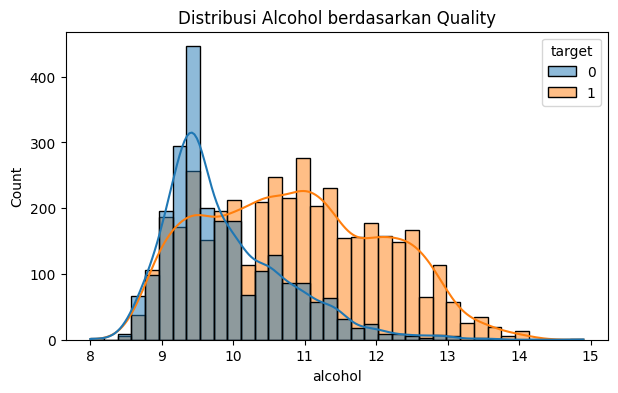

In [32]:

plt.figure(figsize=(7,4))

sns.histplot(
    data=eda_df,
    x="alcohol",
    hue="target",
    kde=True
)

plt.title("Distribusi Alcohol berdasarkan Quality")
plt.show()


## 10. Menghapus Outlier Valid pada kasus Anomali Jarang (True Positive Signal)

In [33]:
# ============================================================
# 10. Menghapus Outlier Valid pada Kasus Anomali Jarang
# (True Positive Signal)
# Dataset: Wine Quality
# Fitur: chlorides
# ============================================================


# Deteksi pencilan pada chlorides menggunakan Tukey's Fences
# (1.5 x IQR)

q1 = eda_df["chlorides"].quantile(0.25)
q3 = eda_df["chlorides"].quantile(0.75)

iqr = q3 - q1

upper_bound = q3 + 1.5 * iqr
lower_bound = q1 - 1.5 * iqr



# Identifikasi baris outlier

mask_outlier = (
    (eda_df["chlorides"] < lower_bound) |
    (eda_df["chlorides"] > upper_bound)
)

outliers = eda_df[mask_outlier]



# ============================================================
# SEBELUM MITIGASI:
# Mengecek apakah outlier memiliki sinyal quality baik
# dibandingkan populasi umum
# ============================================================


prop_outlier_positive = outliers["target"].mean()

prop_population_positive = eda_df["target"].mean()


print(
    f"[Sebelum Mitigasi] "
    f"Proporsi Quality Baik pada Kelompok Outlier: "
    f"{prop_outlier_positive * 100:.2f}%"
)


print(
    f"[Sebelum Mitigasi] "
    f"Proporsi Quality Baik pada Seluruh Dataset: "
    f"{prop_population_positive * 100:.2f}%"
)



# ============================================================
# SESUDAH MITIGASI:
# Tidak menghapus data, tetapi melakukan transformasi
# untuk mempertahankan sinyal anomali
# ============================================================


eda_df_stabil = eda_df.copy()


# Transformasi non-linear
# karena chlorides memiliki distribusi miring

eda_df_stabil["chlorides_log"] = np.log1p(
    eda_df_stabil["chlorides"]
)



# ============================================================
# Validasi bahwa jumlah sampel tetap sama
# ============================================================


print(
    f"[Sesudah Mitigasi] "
    f"Ukuran Sampel Tetap: {len(eda_df_stabil)} data"
)


print(
    "[Sesudah Mitigasi] "
    "Outlier tidak dihapus, hanya distabilkan menggunakan transformasi log"
)

[Sebelum Mitigasi] Proporsi Quality Baik pada Kelompok Outlier: 45.45%
[Sebelum Mitigasi] Proporsi Quality Baik pada Seluruh Dataset: 63.31%
[Sesudah Mitigasi] Ukuran Sampel Tetap: 6497 data
[Sesudah Mitigasi] Outlier tidak dihapus, hanya distabilkan menggunakan transformasi log


# CRISP-DM Implementation Lanjutan: Audit Dataset Wine Quality

Bagian ini menerapkan audit karakteristik dataset sebelum pemodelan:
- Dimensi data (N vs d)
- Tipe fitur
- Missing value dan outlier
- Multikolinearitas VIF
- Karakteristik target
- Pemilihan algoritma berdasarkan karakteristik data


In [ ]:

import numpy as np
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

wine_audit = eda_df.copy() if "eda_df" in globals() else wines.copy()

target_col = "target" if "target" in wine_audit.columns else "quality"

X_audit = wine_audit.drop(columns=[target_col], errors="ignore")
y_audit = wine_audit[target_col]

num_cols = X_audit.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_audit.select_dtypes(exclude=np.number).columns.tolist()

print("=== 1. DIMENSI DATA ===")
N,d = X_audit.shape
print("Jumlah data:",N)
print("Jumlah fitur:",d)
print("Rasio N/d:",round(N/d,2))


In [ ]:

print("=== 2. TIPE FITUR ===")
print("Numerik:",num_cols)
print("Kategorikal:",cat_cols if cat_cols else "Tidak ada")


In [ ]:

print("=== 3. MISSING VALUE & OUTLIER ===")

print("Missing value:",wine_audit.isnull().sum().sum())

out=[]
for c in num_cols:
    q1=X_audit[c].quantile(.25)
    q3=X_audit[c].quantile(.75)
    iqr=q3-q1
    n=((X_audit[c]<q1-1.5*iqr)|(X_audit[c]>q3+1.5*iqr)).sum()
    out.append([c,n,round(n/N*100,2)])

pd.DataFrame(out,columns=["Feature","Outlier","Percent"])


In [ ]:

print("=== 4. MULTIKOLINEARITAS VIF ===")

X_vif=X_audit[num_cols].replace([np.inf,-np.inf],np.nan).dropna()

vif=pd.DataFrame({
    "Feature":X_vif.columns,
    "VIF":[variance_inflation_factor(X_vif.values,i)
           for i in range(X_vif.shape[1])]
})

vif.sort_values("VIF",ascending=False)


In [ ]:

print("=== 5. TARGET ANALYSIS ===")

print(y_audit.describe())
print("\nDistribusi target:")
print(y_audit.value_counts().sort_index())


# CRISP-DM Fase Modeling

Algoritma yang dibandingkan:
- Ridge Regression: mengatasi korelasi antar fitur.
- ElasticNet: kombinasi seleksi fitur dan regularisasi.
- KNN Regressor: menangkap pola berdasarkan jarak.
- SVR RBF: menangkap hubungan non-linear.
- Random Forest dan Gradient Boosting: kuat untuk data tabular.


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold,cross_validate
from sklearn.linear_model import Ridge,ElasticNet
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

X=wine_audit.drop(columns=[target_col])
y=wine_audit[target_col]

models={
"Ridge":Pipeline([("scale",StandardScaler()),("model",Ridge(alpha=5))]),
"ElasticNet":Pipeline([("scale",StandardScaler()),("model",ElasticNet(alpha=.01))]),
"KNN":Pipeline([("scale",StandardScaler()),("model",KNeighborsRegressor(n_neighbors=9,weights="distance"))]),
"SVR":Pipeline([("scale",StandardScaler()),("model",SVR(kernel="rbf"))]),
"Random Forest":RandomForestRegressor(n_estimators=200,random_state=42),
"Gradient Boosting":GradientBoostingRegressor(random_state=42)
}

cv=KFold(n_splits=5,shuffle=True,random_state=42)

result=[]

for name,model in models.items():
    s=cross_validate(model,X,y,cv=cv,
                     scoring={"mae":"neg_mean_absolute_error",
                              "rmse":"neg_root_mean_squared_error",
                              "r2":"r2"})
    result.append({
        "Model":name,
        "MAE":-s["test_mae"].mean(),
        "RMSE":-s["test_rmse"].mean(),
        "R2":s["test_r2"].mean()
    })

pd.DataFrame(result).sort_values("RMSE")
